In [44]:
# Importing Libraries
import seaborn as sns
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt 

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

# How are in-demand skills trending for Data Analysts? 

### Methodology

1) Aggregate skill count monthly
2) Re-analyze based on percentage of total jobs
3) Plot the monthly skill demand

In [3]:
df_DA_US = df[(df["job_country"] == "United States") & (df["job_title_short"] == "Data Analyst")].copy()

In [4]:
df_DA_US["job_posted_month_no"] = df_DA_US["job_posted_date"].dt.month # dt.month will extract 1-12 for a month

In [5]:
df_DA_US_explode = df_DA_US.explode("job_skills")

In [6]:
df_DA_US_pivot = df_DA_US_explode.pivot_table(index="job_posted_month_no", columns="job_skills", aggfunc="size", fill_value=0) # for any NaN value they are filled with 0

df_DA_US_pivot

job_skills,airflow,airtable,alteryx,angular,ansible,apl,arch,asana,asp.net,asp.net core,...,watson,webex,windows,wire,word,workfront,wrike,xamarin,yarn,zoom
job_posted_month_no,,,,,,,,,,,,,,,,,,,,,
1,39,7,206,21,7,1,0,15,17,0,...,7,9,80,3,968,0,7,0,0,30
2,35,0,203,23,4,1,0,14,9,0,...,6,6,92,3,738,3,0,0,0,19
3,39,1,219,5,5,6,1,14,11,0,...,7,6,76,5,736,1,1,1,0,16
4,28,1,208,8,3,7,3,5,6,0,...,2,4,86,9,695,8,1,0,0,12
5,27,3,144,15,8,9,1,5,13,0,...,1,6,67,1,557,3,0,0,0,9
6,39,5,188,9,4,8,3,7,7,0,...,5,2,69,8,721,5,0,0,0,20
7,42,2,160,5,3,5,5,6,2,0,...,4,1,59,10,587,0,0,0,1,13
8,44,2,187,5,3,10,0,5,3,0,...,3,6,87,4,752,0,0,0,0,26
9,22,3,145,11,2,3,4,4,3,0,...,0,4,80,4,478,0,0,0,1,12


In [34]:
df_DA_US_pivot.loc["Total"] = df_DA_US_pivot.sum() # it searches for row Total if not finds then creates it - it will be the sum of these columns

In [35]:
df_DA_US_pivot.loc["Total"].sort_values(ascending=False) # its a series with index of sql, excel... and values of 34452, 27519 ...

job_skills
sql          34452
excel        27519
tableau      19311
python       18382
sas          13200
             ...  
msaccess         1
kotlin           1
openstack        1
theano           1
xamarin          1
Name: Total, Length: 218, dtype: int64

In [23]:
df_DA_US_pivot.loc["Total"].sort_values(ascending=False).index

Index(['sql', 'excel', 'tableau', 'python', 'sas', 'r', 'power bi', 'word',
       'powerpoint', 'oracle',
       ...
       'capacitor', 'chainer', 'asp.net core', 'qt', 'microsoft lists',
       'msaccess', 'kotlin', 'openstack', 'theano', 'xamarin'],
      dtype='str', name='job_skills', length=218)

In [36]:
df_DA_US_pivot = df_DA_US_pivot[df_DA_US_pivot.loc["Total"].sort_values(ascending=False).index] # df_DA_US_pivot[selection]; filter by row Total

df_DA_US_pivot

job_skills,sql,excel,tableau,python,sas,r,power bi,word,powerpoint,oracle,...,capacitor,chainer,asp.net core,qt,microsoft lists,msaccess,kotlin,openstack,theano,xamarin
job_posted_month_no,,,,,,,,,,,,,,,,,,,,,
1,4601,3592,2488,2254,1832,1513,1337,968,972,718,...,1,0,0,0,0,0,0,0,0,0
2,3168,2587,1676,1618,1212,1045,1122,738,705,514,...,0,0,0,0,0,0,0,0,0,0
3,3226,2661,1804,1683,1238,1141,1054,736,669,418,...,0,0,0,0,0,0,0,0,0,1
4,3220,2549,1789,1679,1302,1038,1057,695,650,439,...,0,0,0,0,0,0,0,0,0,0
5,2581,2118,1432,1349,972,867,860,557,515,358,...,0,0,0,0,0,1,0,0,0,0
6,2862,2382,1628,1609,984,1017,989,721,624,414,...,0,0,0,1,0,0,1,1,0,0
7,2609,2118,1533,1438,996,881,881,587,549,401,...,0,0,0,0,0,0,0,0,0,0
8,3414,2731,1951,2025,1276,1271,1208,752,746,484,...,0,0,0,0,0,0,0,0,0,0
9,2295,1801,1353,1229,856,746,820,478,475,359,...,0,0,0,0,0,0,0,0,0,0


In [37]:
df_DA_US_pivot = df_DA_US_pivot.drop("Total") # we already sorted so we dont need that Total row anymore

In [38]:
df_DA_US_pivot

job_skills,sql,excel,tableau,python,sas,r,power bi,word,powerpoint,oracle,...,capacitor,chainer,asp.net core,qt,microsoft lists,msaccess,kotlin,openstack,theano,xamarin
job_posted_month_no,,,,,,,,,,,,,,,,,,,,,
1,4601,3592,2488,2254,1832,1513,1337,968,972,718,...,1,0,0,0,0,0,0,0,0,0
2,3168,2587,1676,1618,1212,1045,1122,738,705,514,...,0,0,0,0,0,0,0,0,0,0
3,3226,2661,1804,1683,1238,1141,1054,736,669,418,...,0,0,0,0,0,0,0,0,0,1
4,3220,2549,1789,1679,1302,1038,1057,695,650,439,...,0,0,0,0,0,0,0,0,0,0
5,2581,2118,1432,1349,972,867,860,557,515,358,...,0,0,0,0,0,1,0,0,0,0
6,2862,2382,1628,1609,984,1017,989,721,624,414,...,0,0,0,1,0,0,1,1,0,0
7,2609,2118,1533,1438,996,881,881,587,549,401,...,0,0,0,0,0,0,0,0,0,0
8,3414,2731,1951,2025,1276,1271,1208,752,746,484,...,0,0,0,0,0,0,0,0,0,0
9,2295,1801,1353,1229,856,746,820,478,475,359,...,0,0,0,0,0,0,0,0,0,0


In [39]:
DA_totals = df_DA_US.groupby("job_posted_month_no").size() # to get the number of job postings in each month
DA_totals

job_posted_month_no
1     8494
2     6124
3     6218
4     6049
5     4993
6     5683
7     5201
8     6634
9     4639
10    5271
11    4531
12    3979
dtype: int64

In [40]:
df_DA_US_pivot.div(DA_totals, axis=0) # DataFrame.div(other, axis='columns', level=None, fill_value=None) other - something  to divide by. axis = axis along which to align a 1D Series input against a 2D DataFrame(0 or index, 1 or rows)
# axis = 0 to match the index of DA_totals to the rows of df_DA_US_pivot

job_skills,sql,excel,tableau,python,sas,r,power bi,word,powerpoint,oracle,...,capacitor,chainer,asp.net core,qt,microsoft lists,msaccess,kotlin,openstack,theano,xamarin
job_posted_month_no,,,,,,,,,,,,,,,,,,,,,
1,0.541676,0.422887,0.292913,0.265364,0.215682,0.178126,0.157405,0.113963,0.114434,0.084530,...,0.000118,0.000000,0.00000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000
2,0.517309,0.422436,0.273677,0.264206,0.197910,0.170640,0.183214,0.120509,0.115121,0.083932,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000
3,0.518816,0.427951,0.290125,0.270666,0.199099,0.183500,0.169508,0.118366,0.107591,0.067224,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000161
4,0.532319,0.421392,0.295751,0.277567,0.215242,0.171599,0.174740,0.114895,0.107456,0.072574,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000
5,0.516924,0.424194,0.286802,0.270178,0.194673,0.173643,0.172241,0.111556,0.103144,0.071700,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.0002,0.000000,0.000000,0.000000,0.000000
6,0.503607,0.419145,0.286468,0.283125,0.173148,0.178955,0.174028,0.126870,0.109801,0.072849,...,0.000000,0.000000,0.00000,0.000176,0.000000,0.0000,0.000176,0.000176,0.000000,0.000000
7,0.501634,0.407229,0.294751,0.276485,0.191502,0.169391,0.169391,0.112863,0.105557,0.077101,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000
8,0.514622,0.411667,0.294091,0.305246,0.192342,0.191589,0.182092,0.113355,0.112451,0.072957,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000
9,0.494719,0.388230,0.291658,0.264928,0.184523,0.160811,0.176762,0.103039,0.102393,0.077387,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.0000,0.000000,0.000000,0.000000,0.000000


In [41]:
df_DA_US_percent = df_DA_US_pivot.div(DA_totals/100, axis=0) # to get percent-like view

df_DA_US_percent

job_skills,sql,excel,tableau,python,sas,r,power bi,word,powerpoint,oracle,...,capacitor,chainer,asp.net core,qt,microsoft lists,msaccess,kotlin,openstack,theano,xamarin
job_posted_month_no,,,,,,,,,,,,,,,,,,,,,
1,54.167648,42.288674,29.291264,26.536379,21.568166,17.812574,15.740523,11.396280,11.443372,8.453026,...,0.011773,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,51.730895,42.243632,27.367734,26.420640,19.790986,17.064010,18.321359,12.050947,11.512084,8.393207,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,51.881634,42.795111,29.012544,27.066581,19.909939,18.349952,16.950788,11.836603,10.759087,6.722419,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.016082
4,53.231939,42.139197,29.575136,27.756654,21.524219,17.159861,17.473963,11.489502,10.745578,7.257398,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5,51.692369,42.419387,28.680152,27.017825,19.467254,17.364310,17.224114,11.155618,10.314440,7.170038,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.020028,0.000000,0.000000,0.000000,0.000000
6,50.360725,41.914482,28.646841,28.312511,17.314799,17.895478,17.402780,12.686961,10.980116,7.284885,...,0.000000,0.000000,0.000000,0.017596,0.000000,0.000000,0.017596,0.017596,0.000000,0.000000
7,50.163430,40.722938,29.475101,27.648529,19.150163,16.939050,16.939050,11.286291,10.555662,7.710056,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
8,51.462165,41.166717,29.409105,30.524570,19.234248,19.158879,18.209225,11.335544,11.245101,7.295749,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
9,49.471869,38.823022,29.165768,26.492779,18.452253,16.081052,17.676223,10.303945,10.239276,7.738737,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [42]:
# to have months not in numbers but as names

df_DA_US_percent = df_DA_US_percent.reset_index()
df_DA_US_percent['job_posted_month'] = df_DA_US_percent['job_posted_month_no'].apply(lambda x: pd.to_datetime(x, format='%m').strftime('%b'))
df_DA_US_percent = df_DA_US_percent.set_index('job_posted_month')
df_DA_US_percent = df_DA_US_percent.drop(columns='job_posted_month_no')


In [43]:
df_DA_US_percent

job_skills,sql,excel,tableau,python,sas,r,power bi,word,powerpoint,oracle,...,capacitor,chainer,asp.net core,qt,microsoft lists,msaccess,kotlin,openstack,theano,xamarin
job_posted_month,,,,,,,,,,,,,,,,,,,,,
Jan,54.167648,42.288674,29.291264,26.536379,21.568166,17.812574,15.740523,11.396280,11.443372,8.453026,...,0.011773,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Feb,51.730895,42.243632,27.367734,26.420640,19.790986,17.064010,18.321359,12.050947,11.512084,8.393207,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Mar,51.881634,42.795111,29.012544,27.066581,19.909939,18.349952,16.950788,11.836603,10.759087,6.722419,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.016082
Apr,53.231939,42.139197,29.575136,27.756654,21.524219,17.159861,17.473963,11.489502,10.745578,7.257398,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
May,51.692369,42.419387,28.680152,27.017825,19.467254,17.364310,17.224114,11.155618,10.314440,7.170038,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.020028,0.000000,0.000000,0.000000,0.000000
Jun,50.360725,41.914482,28.646841,28.312511,17.314799,17.895478,17.402780,12.686961,10.980116,7.284885,...,0.000000,0.000000,0.000000,0.017596,0.000000,0.000000,0.017596,0.017596,0.000000,0.000000
Jul,50.163430,40.722938,29.475101,27.648529,19.150163,16.939050,16.939050,11.286291,10.555662,7.710056,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Aug,51.462165,41.166717,29.409105,30.524570,19.234248,19.158879,18.209225,11.335544,11.245101,7.295749,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Sep,49.471869,38.823022,29.165768,26.492779,18.452253,16.081052,17.676223,10.303945,10.239276,7.738737,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


<Axes: xlabel='job_posted_month'>

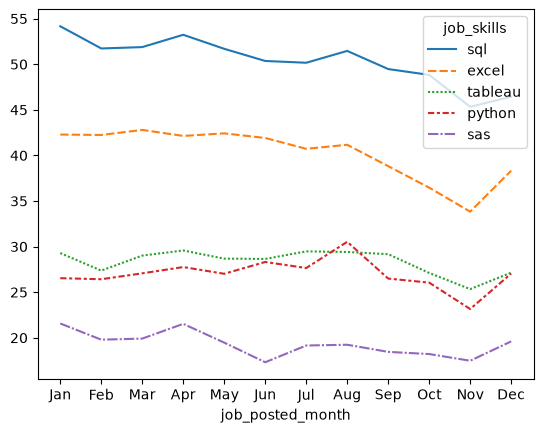

In [ ]:
df_plot = df_DA_US_percent.iloc[:, :5] # [all the rows, only 5 first values]

sns.lineplot(data=df_plot)

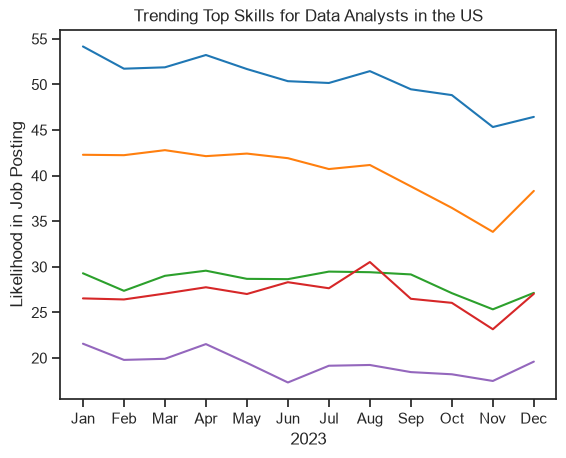

In [48]:
sns.lineplot(data=df_plot, dashes=False, palette="tab10") # to remove dashes and have solid lines instead
sns.set_theme(style="ticks")

plt.title('Trending Top Skills for Data Analysts in the US')
plt.ylabel('Likelihood in Job Posting')
plt.xlabel('2023')
plt.legend().remove()

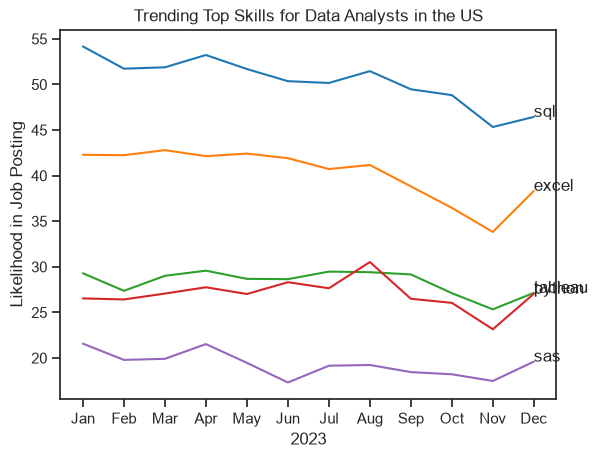

In [ ]:
sns.lineplot(data=df_plot, dashes=False, palette="tab10") # to remove dashes and have solid lines instead
sns.set_theme(style="ticks")

plt.title('Trending Top Skills for Data Analysts in the US')
plt.ylabel('Likelihood in Job Posting')
plt.xlabel('2023')
plt.legend().remove()

for i in range(5):
    plt.text(11.2, df_plot.iloc[-1, i], df_plot.columns[i]) #text(x coord, y coord, text to plot), Jan is index 0 so Dec is index 11->11.2 so its not that close; for y coord we want percent value in Dec which is last row "-1"



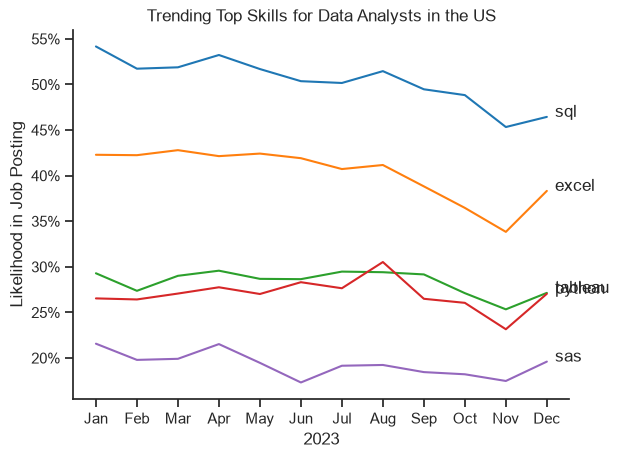

In [53]:
sns.lineplot(data=df_plot, dashes=False, palette="tab10") # to remove dashes and have solid lines instead
sns.set_theme(style="ticks")
sns.despine()

plt.title('Trending Top Skills for Data Analysts in the US')
plt.ylabel('Likelihood in Job Posting')
plt.xlabel('2023')
plt.legend().remove()

from matplotlib.ticker import PercentFormatter 
ax = plt.gca()
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))

for i in range(5):
    plt.text(11.2, df_plot.iloc[-1, i], df_plot.columns[i]) #text(x coord, y coord, text to plot), Jan is index 0 so Dec is index 11->11.2 so its not that close; for y coord we want percent value in Dec which is last row "-1"



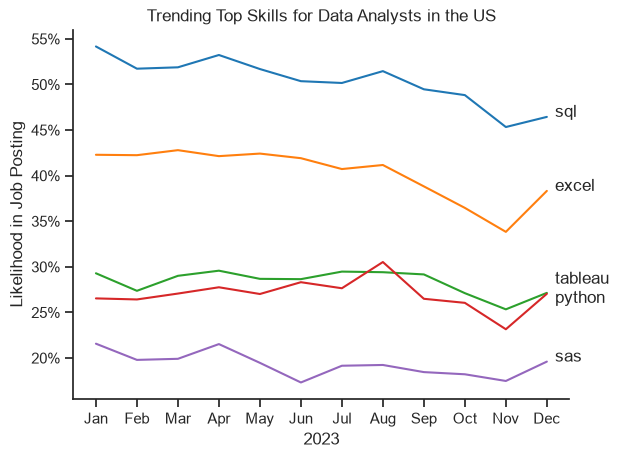

In [55]:
sns.lineplot(data=df_plot, dashes=False, palette="tab10") 
sns.set_theme(style="ticks")
sns.despine()

plt.title('Trending Top Skills for Data Analysts in the US')
plt.ylabel('Likelihood in Job Posting')
plt.xlabel('2023')
plt.legend().remove()

from matplotlib.ticker import PercentFormatter 
ax = plt.gca()
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))

for i in range(5):
    skill_name = df_plot.columns[i]
    y_pos = df_plot.iloc[-1, i]

    # Adjust y-position slightly for colliding labels
    if skill_name == "tableau":
        y_pos += 1.0  # Move up (use 0.01 if your data is decimal 0.27 instead of 27)
    elif skill_name == "python":
        y_pos -= 1.0  # Move down (use -0.01 if your data is decimal 0.27 instead of 27)

    # Make sure to pass y_pos here instead of df_plot.iloc[-1, i]
    plt.text(11.2, y_pos, skill_name)
